In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans

t = pd.read_parquet("../data/processed/turbines.parquet")
active = t[t["decommissioned"].isna() | (t["decommissioned"] >= "2021-01-01")]
on = active[active["location_type"] == "onshore"].copy()

LAT0 = 51.0
on["x_km"] = on["lon"] * 111.32 * np.cos(np.radians(LAT0))
on["y_km"] = on["lat"] * 110.57

print(
    on.groupby("zone").agg(
        turbines=("unit_id", "count"), gw=("capacity_kw", lambda s: round(s.sum() / 1e6, 1))
    )
)

            turbines    gw
zone                      
50Hertz        11532  24.4
Amprion         7095  16.8
TenneT         13697  31.3
TransnetBW       989   2.4


In [2]:
def weighted_quantile(values, weights, q):
    order = np.argsort(values)
    v, w = values[order], weights[order]
    cum = np.cumsum(w) / w.sum()
    return v[np.searchsorted(cum, q)]


def cluster_zone(d, k, seed=0):
    X = d[["x_km", "y_km"]].to_numpy()
    w = d["capacity_kw"].to_numpy()
    km = KMeans(n_clusters=k, n_init=10, random_state=seed).fit(X, sample_weight=w)
    dist = np.linalg.norm(X - km.cluster_centers_[km.labels_], axis=1)
    return km.labels_, dist


rows = []
for zone, d in on.groupby("zone"):
    w = d["capacity_kw"].to_numpy()
    for k in [20, 50, 100]:
        _, dist = cluster_zone(d, k)
        rows.append(
            {
                "zone": zone,
                "k": k,
                "mean_km": np.average(dist, weights=w),
                "p90_km": weighted_quantile(dist, w, 0.9),
            }
        )

res = pd.DataFrame(rows)
print(res.pivot(index="zone", columns="k", values=["mean_km", "p90_km"]).round(1))

           mean_km            p90_km            
k              20    50   100    20    50    100
zone                                            
50Hertz       21.9  12.2  7.4   35.8  20.8  13.0
Amprion       17.5   9.9  6.2   29.4  17.1  11.1
TenneT        24.1  13.8  8.9   40.1  23.5  15.6
TransnetBW     8.2   3.8  1.5   15.4   7.1   3.1


K=20: 80 onshore locations, 76,560 location-runs for the backfill
K=50: 200 onshore locations, 191,400 location-runs for the backfill
K=100: 400 onshore locations, 382,800 location-runs for the backfill


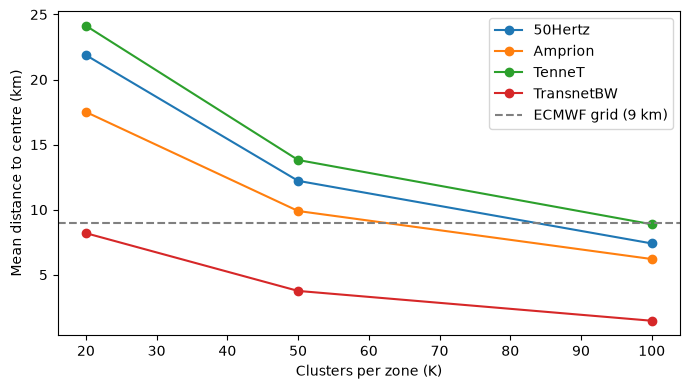

In [3]:
fig, ax = plt.subplots(figsize=(7, 4))
for zone, d in res.groupby("zone"):
    ax.plot(d["k"], d["mean_km"], marker="o", label=zone)
ax.axhline(9, color="grey", linestyle="--", label="ECMWF grid (9 km)")
ax.set_xlabel("Clusters per zone (K)")
ax.set_ylabel("Mean distance to centre (km)")
ax.legend()
plt.tight_layout()

runs = 957
for k in [20, 50, 100]:
    locations = 4 * k
    print(
        f"K={k}: {locations} onshore locations, {locations * runs:,} location-runs for the backfill"
    )

In [4]:
off = active[active["location_type"] == "offshore"].copy()
LAT_OFF = 54.5
off["x_km"] = off["lon"] * 111.32 * np.cos(np.radians(LAT_OFF))
off["y_km"] = off["lat"] * 110.57

print(
    off.groupby("zone").agg(
        turbines=("unit_id", "count"), gw=("capacity_kw", lambda s: round(s.sum() / 1e6, 2))
    ),
    "\n",
)

by_name = off.groupby(["zone", "wind_farm"], dropna=False).agg(
    turbines=("unit_id", "count"),
    mw=("capacity_kw", lambda s: round(s.sum() / 1000)),
    spread_km=("x_km", lambda s: round(s.max() - s.min(), 1)),
)
print("Distinct names:", len(by_name))
by_name.sort_values("mw", ascending=False)

         turbines    gw
zone                   
50Hertz       329  2.14
TenneT       1488  9.49 

Distinct names: 48


turbines   mw  spread_km
zone    wind_farm                                                    
TenneT  Borkum Riffgrund 3                         83  959       13.6
        EnBW He Dreiht                             61  915       10.1
        Windpark Hohe See                          71  522        8.1
50Hertz Baltic Eagle                               50  476        7.8
TenneT  Borkum Riffgrund 2                         56  465       12.6
        OWP Veja Mate                              67  422        6.4
        Merkur Offshore                            66  406        7.5
        Global Tech I                              80  400        6.3
50Hertz Arkona Becken Süd-Ost                      60  378        8.0
        WIKINGER                                   70  366        6.1
TenneT  Gode Wind 1                                55  345        8.1
        OWP Kaskasi                                38  342        7.3
        Nordsee One                                54  332       10.0
        Borkum Riffgrund 1                         78  327        8.1
50Hertz OWP Windanker                              21  315        4.7
TenneT  Meerwind Süd|Ost                           80  302        8.1
        OWP DanTysk                                80  302        5.1
        OWP Sandbank                               72  302        7.1
50Hertz Baltic 2                                   80  302        9.5
TenneT  Butendiek                                  80  288        4.0
        Gode Wind 3                                23  266        4.6
        Gode Wind 2                                42  263        9.0
        Deutsche Bucht                             31  260        4.8
50Hertz Arcadis Ost I                              27  257       11.0
TenneT  NC 1                                       15  225        3.9
        Amrumbank-West                             58  219        8.9
        Trianel Windpark Borkum, Bauphase 2        32  203        6.7
        Trianel Windpark Borkum                    40  200        4.8
        OWP Nordsee Ost 2                          24  148        5.5
        OWP Nordsee Ost 1                          24  148        6.4
        Windpark Albatros                          16  118        6.1
        RIFFGAT                                    30  113        5.0
        OWP Nordergründe                           18  111        2.1
        Amrumbank West                             22   83        8.9
        alpha ventus                               12   60        1.7
50Hertz Baltic 1                                   21   48        4.0
TenneT  Bard Offshore 1 - C9 - 51573657597          8   44        3.4
        Bard Offshore 1 - C12 - 51573657638         8   44        0.9
        Bard Offshore 1 - C2 - 51573657521          8   44        1.1
        Bard Offshore 1 - C3 - 51573657539          8   44        0.8
        Bard Offshore 1 - C4 - 51573657547          8   44        2.4
        Bard Offshore 1 - C5 - 51573657555          8   44        1.7
        Bard Offshore 1 - C6 - 51573657563          8   44        0.9
        Bard Offshore 1 - C1 - 51573657505          8   44        0.0
        Bard Offshore 1 - C8 - 51573657589          4   22        2.3
        Bard Offshore 1 - C10 - 51573657604         4   22        1.7
        Bard Offshore 1 - C11 - 51573657620         4   22        0.8
        Bard Offshore 1 - C7 - 51573657571          4   22        3.0

In [7]:
from sklearn.cluster import AgglomerativeClustering

off["cluster"] = -1
for _zone, d in off.groupby("zone"):
    ac = AgglomerativeClustering(n_clusters=None, distance_threshold=5, linkage="single").fit(
        d[["x_km", "y_km"]]
    )
    off.loc[d.index, "cluster"] = ac.labels_

by_position = off.groupby(["zone", "cluster"]).agg(
    turbines=("unit_id", "count"),
    mw=("capacity_kw", lambda s: round(s.sum() / 1000)),
    width_km=("x_km", lambda s: round(s.max() - s.min(), 1)),
    names=("wind_farm", lambda s: ", ".join(map(str, s.dropna().unique()[:3]))),
)
print("Clusters by position:", len(by_position))
by_position.sort_values("mw", ascending=False)

Clusters by position: 17


turbines    mw  width_km  \
zone    cluster                             
TenneT  1             284  1661      13.2   
        0             189  1430      25.0   
        11            246  1242       8.9   
        5             178  1122      17.7   
50Hertz 1             150  1053      12.4   
TenneT  10            167  1039      13.8   
        4              83   959      13.6   
        2              61   915      10.1   
50Hertz 0              77   733      22.5   
        4              80   302       9.5   
TenneT  6              72   302       7.1   
        3              80   302       5.1   
        8              80   288       4.0   
        9              30   113       5.0   
        7              18   111       2.1   
50Hertz 2              21    48       4.0   
        3               1     6       0.0   

                                                             names  
zone    cluster                                                     
TenneT  1        Merkur Offshore, Trianel Windpark Borkum, Baup...  
        0                    Gode Wind 2, Nordsee One, Gode Wind 1  
        11       Amrumbank West, Amrumbank-West, OWP Nordsee Ost 1  
        5        OWP Veja Mate, Deutsche Bucht, Bard Offshore 1...  
50Hertz 1           Arkona Becken Süd-Ost, WIKINGER, OWP Windanker  
TenneT  10       Windpark Hohe See, Windpark Albatros, Global T...  
        4                                       Borkum Riffgrund 3  
        2                                           EnBW He Dreiht  
50Hertz 0                              Baltic Eagle, Arcadis Ost I  
        4                                                 Baltic 2  
TenneT  6                                             OWP Sandbank  
        3                                              OWP DanTysk  
        8                                                Butendiek  
        9                                                  RIFFGAT  
        7                                         OWP Nordergründe  
50Hertz 2                                                 Baltic 1  
        3                                    Arkona Becken Süd-Ost

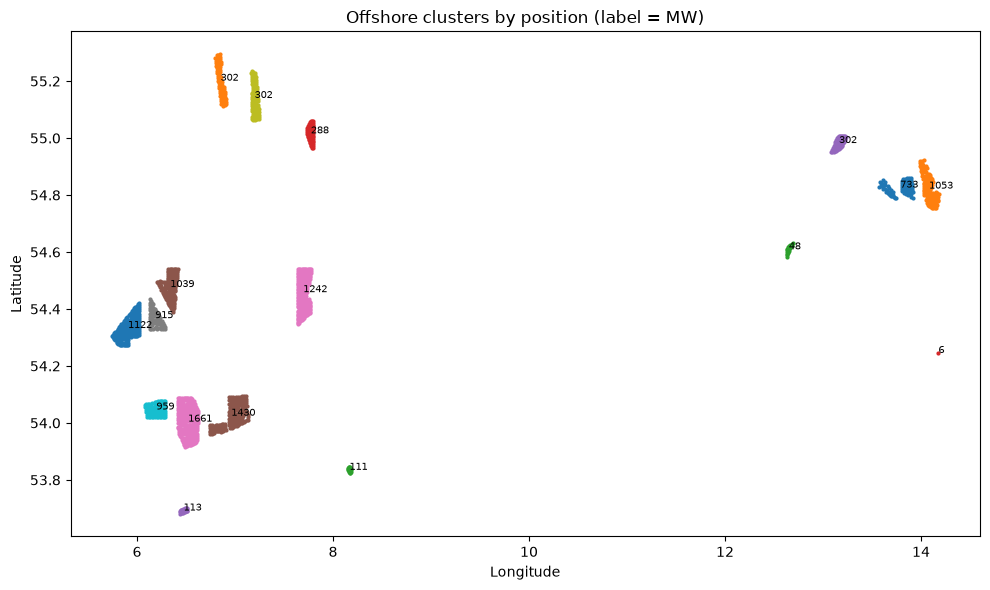

In [9]:
fig, ax = plt.subplots(figsize=(10, 6))
for _key, d in off.groupby(["zone", "cluster"]):
    ax.scatter(d["lon"], d["lat"], s=4)
    ax.annotate(
        f"{d['capacity_kw'].sum() / 1000:.0f}", (d["lon"].mean(), d["lat"].mean()), fontsize=7
    )
ax.set_title("Offshore clusters by position (label = MW)")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
plt.tight_layout()